In [86]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline 
sns.set(color_codes=True)
from scipy.stats import poisson


In [2]:
df = pd.read_csv("20260327_Notas_y_Egresados_Enseñanza_Media_2025_PUBL.csv")

In [3]:
df.shape

(290825, 21)

In [4]:
df.head()

,AGNO,RBD,DGV_RBD,COD_REG_RBD,NOM_REG_RBD_A,COD_PRO_RBD,COD_COM_RBD,NOM_COM_RBD,COD_DEPROV_RBD,NOM_DEPROV_RBD,...,COD_GRADO,COD_DEPE,COD_DEPE2,RURAL_RBD,MRUN,MRUN_IPE,PROM_NOTAS_ALU,ORIGEN,ENSE_COMPLETA,MARCA_EGRESO
0,2025,2308,6.0,6.0,LGBO,61.0,6115.0,RENGO,61.0,CACHAPOAL,...,4,3.0,2.0,0.0,89,NaN,61.0,SIGE,1,1
1,2025,17810,1.0,8.0,BBIO,82.0,8203.0,CAÑETE,84.0,ARAUCO,...,4,3.0,2.0,0.0,129,NaN,60.0,SIGE,1,1
2,2025,12305,6.0,5.0,VALPO,58.0,5804.0,VILLA ALEMANA,53.0,VALPARAÍSO,...,4,3.0,2.0,0.0,258,NaN,53.0,SIGE,1,1
3,2025,8005,5.0,10.0,LAGOS,102.0,10201.0,CASTRO,102.0,CHILOÉ,...,4,6.0,5.0,0.0,259,NaN,57.0,SIGE,1,1
4,2025,60,4.0,15.0,AYP,151.0,15101.0,ARICA,151.0,ARICA,...,4,3.0,2.0,0.0,326,NaN,63.0,SIGE,1,1


In [5]:
df.describe()

,AGNO,RBD,DGV_RBD,COD_REG_RBD,COD_PRO_RBD,COD_COM_RBD,COD_DEPROV_RBD,COD_ENSE,COD_GRADO,COD_DEPE,COD_DEPE2,RURAL_RBD,MRUN,MRUN_IPE,PROM_NOTAS_ALU,ENSE_COMPLETA,MARCA_EGRESO
count,290825.0,290825.000000,281940.000000,281939.000000,281939.000000,281939.000000,281939.000000,290825.000000,290825.000000,281939.000000,281939.000000,281939.000000,2.908250e+05,1.507500e+04,282186.000000,290825.0,290825.000000
mean,2025.0,12049.609280,4.457062,9.375209,95.691845,9575.524298,94.020579,376.690250,3.933066,3.246596,2.314089,0.033380,1.396640e+07,2.625776e+07,59.951475,1.0,0.967441
std,0.0,9566.592907,2.879106,4.010426,39.899787,3992.667939,39.258032,102.951697,0.390752,1.342484,1.249776,0.179626,8.171321e+06,1.821352e+06,6.168528,0.0,0.177480
min,2025.0,0.000000,0.000000,1.000000,11.000000,1101.000000,11.000000,310.000000,1.000000,1.000000,1.000000,0.000000,8.900000e+01,1.301430e+05,18.000000,1.0,0.000000
25%,2025.0,4277.000000,2.000000,6.000000,61.000000,6105.000000,61.000000,310.000000,4.000000,3.000000,2.000000,0.000000,6.948563e+06,2.560281e+07,56.000000,1.0,1.000000
50%,2025.0,9877.000000,4.000000,10.000000,101.000000,10101.000000,92.000000,310.000000,4.000000,3.000000,2.000000,0.000000,1.384935e+07,2.614468e+07,61.000000,1.0,1.000000
75%,2025.0,17833.000000,7.000000,13.000000,131.000000,13122.000000,133.000000,410.000000,4.000000,4.000000,3.000000,0.000000,2.080564e+07,2.719090e+07,65.000000,1.0,1.000000
max,2025.0,95850.000000,9.000000,16.000000,163.000000,16305.000000,151.000000,910.000000,4.000000,6.000000,5.000000,1.000000,2.848344e+07,2.848344e+07,70.000000,1.0,1.000000


In [6]:
Columns_Eliminate = ["COD_REG_RBD", "COD_PRO_RBD", "COD_COM_RBD","COD_DEPROV_RBD","COD_DEPE","ORIGEN","DGV_RBD","MRUN_IPE","AGNO"]
df = df.drop(columns=Columns_Eliminate)

In [7]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290825 entries, 0 to 290824
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   RBD             290825 non-null  int64  
 1   NOM_REG_RBD_A   281939 non-null  object 
 2   NOM_COM_RBD     281939 non-null  object 
 3   NOM_DEPROV_RBD  281939 non-null  object 
 4   COD_ENSE        290825 non-null  int64  
 5   COD_GRADO       290825 non-null  int64  
 6   COD_DEPE2       281939 non-null  float64
 7   RURAL_RBD       281939 non-null  float64
 8   MRUN            290825 non-null  int64  
 9   PROM_NOTAS_ALU  282186 non-null  float64
 10  ENSE_COMPLETA   290825 non-null  int64  
 11  MARCA_EGRESO    290825 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 26.6+ MB


In [8]:
Category_columns = { "COD_DEPE2": "category", "RURAL_RBD": "category", "ENSE_COMPLETA": "category", "MARCA_EGRESO": "category", "COD_ENSE": "category","COD_GRADO": "category"}
df = df.astype(Category_columns)

In [9]:
df

,RBD,NOM_REG_RBD_A,NOM_COM_RBD,NOM_DEPROV_RBD,COD_ENSE,COD_GRADO,COD_DEPE2,RURAL_RBD,MRUN,PROM_NOTAS_ALU,ENSE_COMPLETA,MARCA_EGRESO
0,2308,LGBO,RENGO,CACHAPOAL,310,4,2.0,0.0,89,61.0,1,1
1,17810,BBIO,CAÑETE,ARAUCO,363,4,2.0,0.0,129,60.0,1,1
2,12305,VALPO,VILLA ALEMANA,VALPARAÍSO,310,4,2.0,0.0,258,53.0,1,1
3,8005,LAGOS,CASTRO,CHILOÉ,510,4,5.0,0.0,259,57.0,1,1
4,60,AYP,ARICA,ARICA,310,4,2.0,0.0,326,63.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
290820,0,NaN,NaN,NaN,310,4,NaN,NaN,28483437,NaN,1,1
290821,0,NaN,NaN,NaN,310,1,NaN,NaN,28483438,NaN,1,0
290822,0,NaN,NaN,NaN,310,2,NaN,NaN,28483438,NaN,1,0
290823,0,NaN,NaN,NaN,310,3,NaN,NaN,28483438,NaN,1,0


In [10]:
df.isnull().sum()

RBD                  0
NOM_REG_RBD_A     8886
NOM_COM_RBD       8886
NOM_DEPROV_RBD    8886
COD_ENSE             0
COD_GRADO            0
COD_DEPE2         8886
RURAL_RBD         8886
MRUN                 0
PROM_NOTAS_ALU    8639
ENSE_COMPLETA        0
MARCA_EGRESO         0
dtype: int64

In [11]:
dfc= df.dropna().copy()

In [12]:
dfc.isnull().sum()

RBD               0
NOM_REG_RBD_A     0
NOM_COM_RBD       0
NOM_DEPROV_RBD    0
COD_ENSE          0
COD_GRADO         0
COD_DEPE2         0
RURAL_RBD         0
MRUN              0
PROM_NOTAS_ALU    0
ENSE_COMPLETA     0
MARCA_EGRESO      0
dtype: int64

In [13]:
dfc

,RBD,NOM_REG_RBD_A,NOM_COM_RBD,NOM_DEPROV_RBD,COD_ENSE,COD_GRADO,COD_DEPE2,RURAL_RBD,MRUN,PROM_NOTAS_ALU,ENSE_COMPLETA,MARCA_EGRESO
0,2308,LGBO,RENGO,CACHAPOAL,310,4,2.0,0.0,89,61.0,1,1
1,17810,BBIO,CAÑETE,ARAUCO,363,4,2.0,0.0,129,60.0,1,1
2,12305,VALPO,VILLA ALEMANA,VALPARAÍSO,310,4,2.0,0.0,258,53.0,1,1
3,8005,LAGOS,CASTRO,CHILOÉ,510,4,5.0,0.0,259,57.0,1,1
4,60,AYP,ARICA,ARICA,310,4,2.0,0.0,326,63.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
290537,20440,RM,RECOLETA,SANTIAGO NORTE,310,2,1.0,0.0,28483366,67.0,1,0
290538,20440,RM,RECOLETA,SANTIAGO NORTE,310,4,1.0,0.0,28483366,68.0,1,1
290587,578,COQ,LA SERENA,ELQUI,310,3,5.0,0.0,28483379,55.0,1,0
290588,578,COQ,LA SERENA,ELQUI,310,4,5.0,0.0,28483379,57.0,1,1


In [14]:
dfc = dfc.rename(columns={"RBD": "School ID", "NOM_REG_RBD_A": "Region","NOM_COM_RBD": "Municipality",  "NOM_DEPROV_RBD": "Provincial Department of Education ", "COD_ENSE": "Education level ", "COD_GRADO": "Grade level ","COD_DEPE2": "School dependency","RURAL_RBD": "School rurality","MRUN": "Student ID","PROM_NOTAS_ALU": "GPA","ENSE_COMPLETA": "Complete high school","MARCA_EGRESO": "Graduation status indicator"})

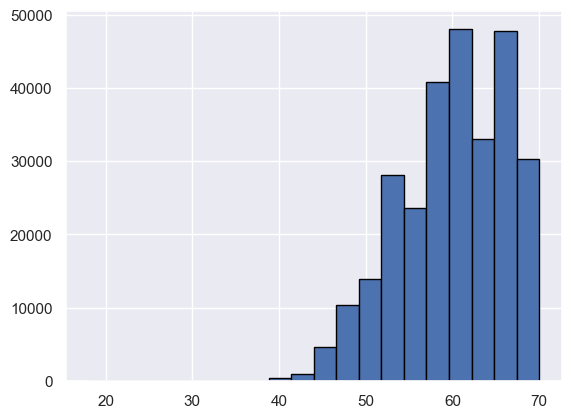

In [15]:
dfc['GPA'].hist(bins=20, edgecolor='black')
plt.show()

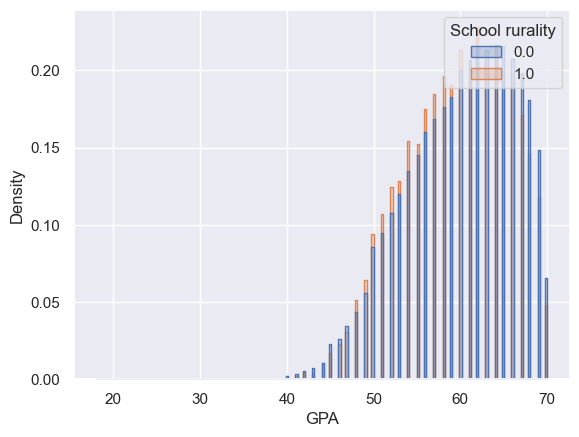

In [16]:
sns.histplot(data=dfc, x='GPA', hue="School rurality",stat="density",common_norm=False,element="step")
plt.show()

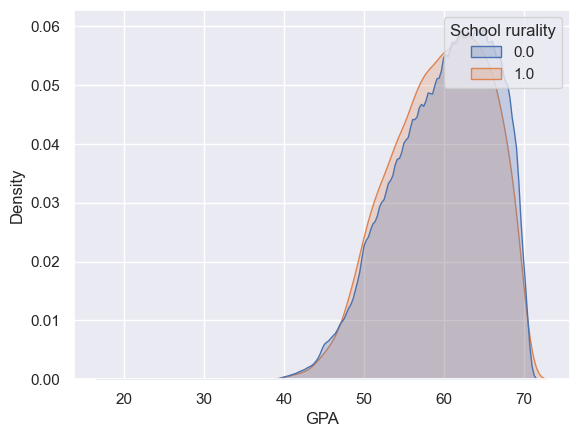

In [18]:
sns.kdeplot(data=dfc, x='GPA', hue="School rurality",common_norm=False, fill=True)
plt.show()

In [19]:
dfc

,School ID,Region,Municipality,Provincial Department of Education,Education level,Grade level,School dependency,School rurality,Student ID,GPA,Complete high school,Graduation status indicator
0,2308,LGBO,RENGO,CACHAPOAL,310,4,2.0,0.0,89,61.0,1,1
1,17810,BBIO,CAÑETE,ARAUCO,363,4,2.0,0.0,129,60.0,1,1
2,12305,VALPO,VILLA ALEMANA,VALPARAÍSO,310,4,2.0,0.0,258,53.0,1,1
3,8005,LAGOS,CASTRO,CHILOÉ,510,4,5.0,0.0,259,57.0,1,1
4,60,AYP,ARICA,ARICA,310,4,2.0,0.0,326,63.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
290537,20440,RM,RECOLETA,SANTIAGO NORTE,310,2,1.0,0.0,28483366,67.0,1,0
290538,20440,RM,RECOLETA,SANTIAGO NORTE,310,4,1.0,0.0,28483366,68.0,1,1
290587,578,COQ,LA SERENA,ELQUI,310,3,5.0,0.0,28483379,55.0,1,0
290588,578,COQ,LA SERENA,ELQUI,310,4,5.0,0.0,28483379,57.0,1,1


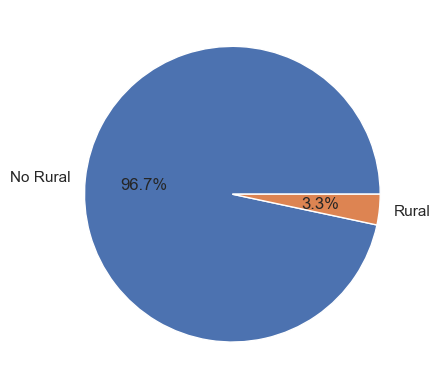

In [121]:
dfc['School rurality'].map({1: 'Rural', 0: 'No Rural'}).value_counts().plot.pie(
    autopct='%1.1f%%')
plt.ylabel('')
plt.show()

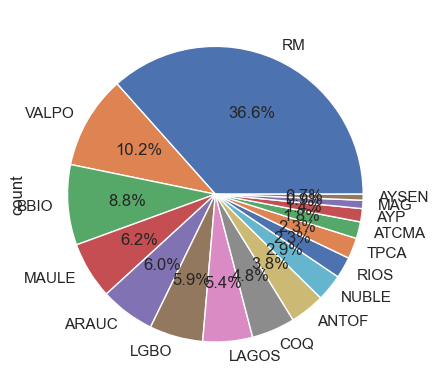

In [125]:
dfc['Region'].value_counts().plot.pie(autopct='%1.1f%%')
plt.show()

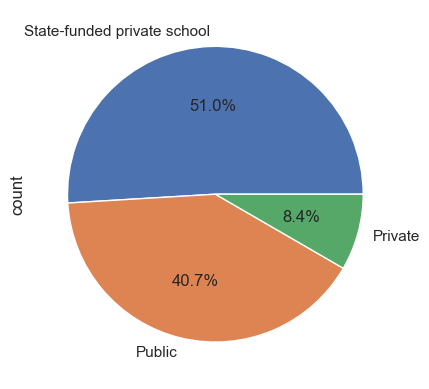

In [124]:
dfc['School_dependency_Public_Private'].value_counts().plot.pie(autopct='%1.1f%%')
plt.show()

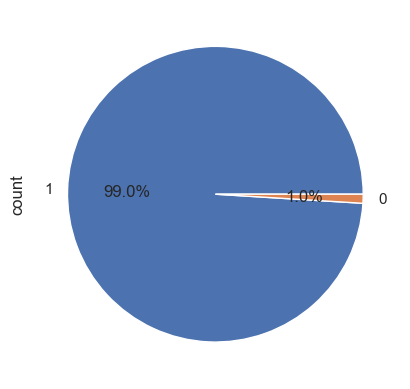

In [127]:
dfc['Graduation status indicator'].value_counts().plot.pie(autopct='%1.1f%%')
plt.show()

In [20]:
Public = [1, 4, 5]
Private=[3]
conditions = [dfc['School dependency'].isin(Public), dfc['School dependency'].isin(Private)]
results = ['Public', 'Private']
dfc['School_dependency_Public_Private'] = np.select(conditions, results, default="State-funded private school")

In [21]:
dfc['GPA'] = dfc['GPA'].astype('float64')

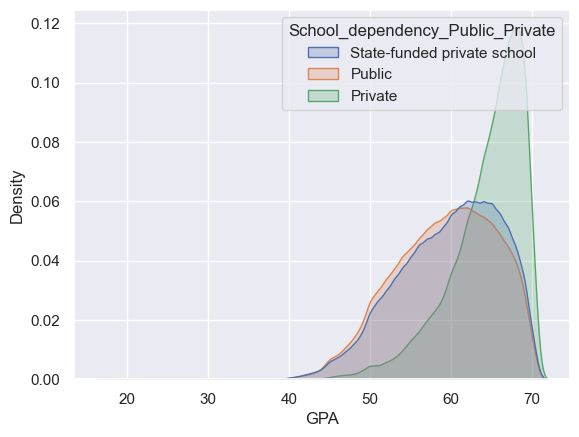

In [22]:
sns.kdeplot(data=dfc, x='GPA', hue='School_dependency_Public_Private',common_norm=False, fill=True)
plt.show()

In [23]:
Gpa = dfc.groupby('Region')['GPA'].agg(Promedio='mean',Desviacion_Estandar='std', Mediana='median',Moda=lambda x: x.mode()[0]).round(2).reset_index()
display(Gpa)

,Region,Promedio,Desviacion_Estandar,Mediana,Moda
0,ANTOF,59.94,5.87,61.0,60.0
1,ARAUC,59.33,6.05,60.0,61.0
2,ATCMA,58.79,6.61,59.0,60.0
3,AYP,60.64,6.15,62.0,66.0
4,AYSEN,59.48,6.14,60.0,65.0
5,BBIO,60.30,6.08,61.0,65.0
6,COQ,59.85,6.05,61.0,63.0
7,LAGOS,59.31,5.96,60.0,62.0
8,LGBO,59.49,6.47,60.0,62.0
9,MAG,60.86,5.71,62.0,62.0


In [51]:
Gpa = dfc.groupby('Municipality')['GPA'].agg(Promedio='mean',Desviacion_Estandar='std', Mediana='median',Moda=lambda x: x.mode()[0]).round(2).reset_index()
display(Gpa)

,Municipality,Promedio,Desviacion_Estandar,Mediana,Moda
0,ALGARROBO,62.06,5.14,63.0,64.0
1,ALHUÉ,60.59,6.65,62.0,63.0
2,ALTO BIOBÍO,58.10,5.57,59.0,59.0
3,ALTO DEL CARMEN,57.53,5.14,57.0,54.0
4,ALTO HOSPICIO,59.95,5.66,61.0,63.0
...,...,...,...,...,...
327,YUMBEL,60.80,5.55,62.0,65.0
328,YUNGAY,61.83,6.28,63.0,66.0
329,ZAPALLAR,59.80,6.62,61.0,64.0
330,ÑIQUÉN,61.86,5.58,63.0,58.0


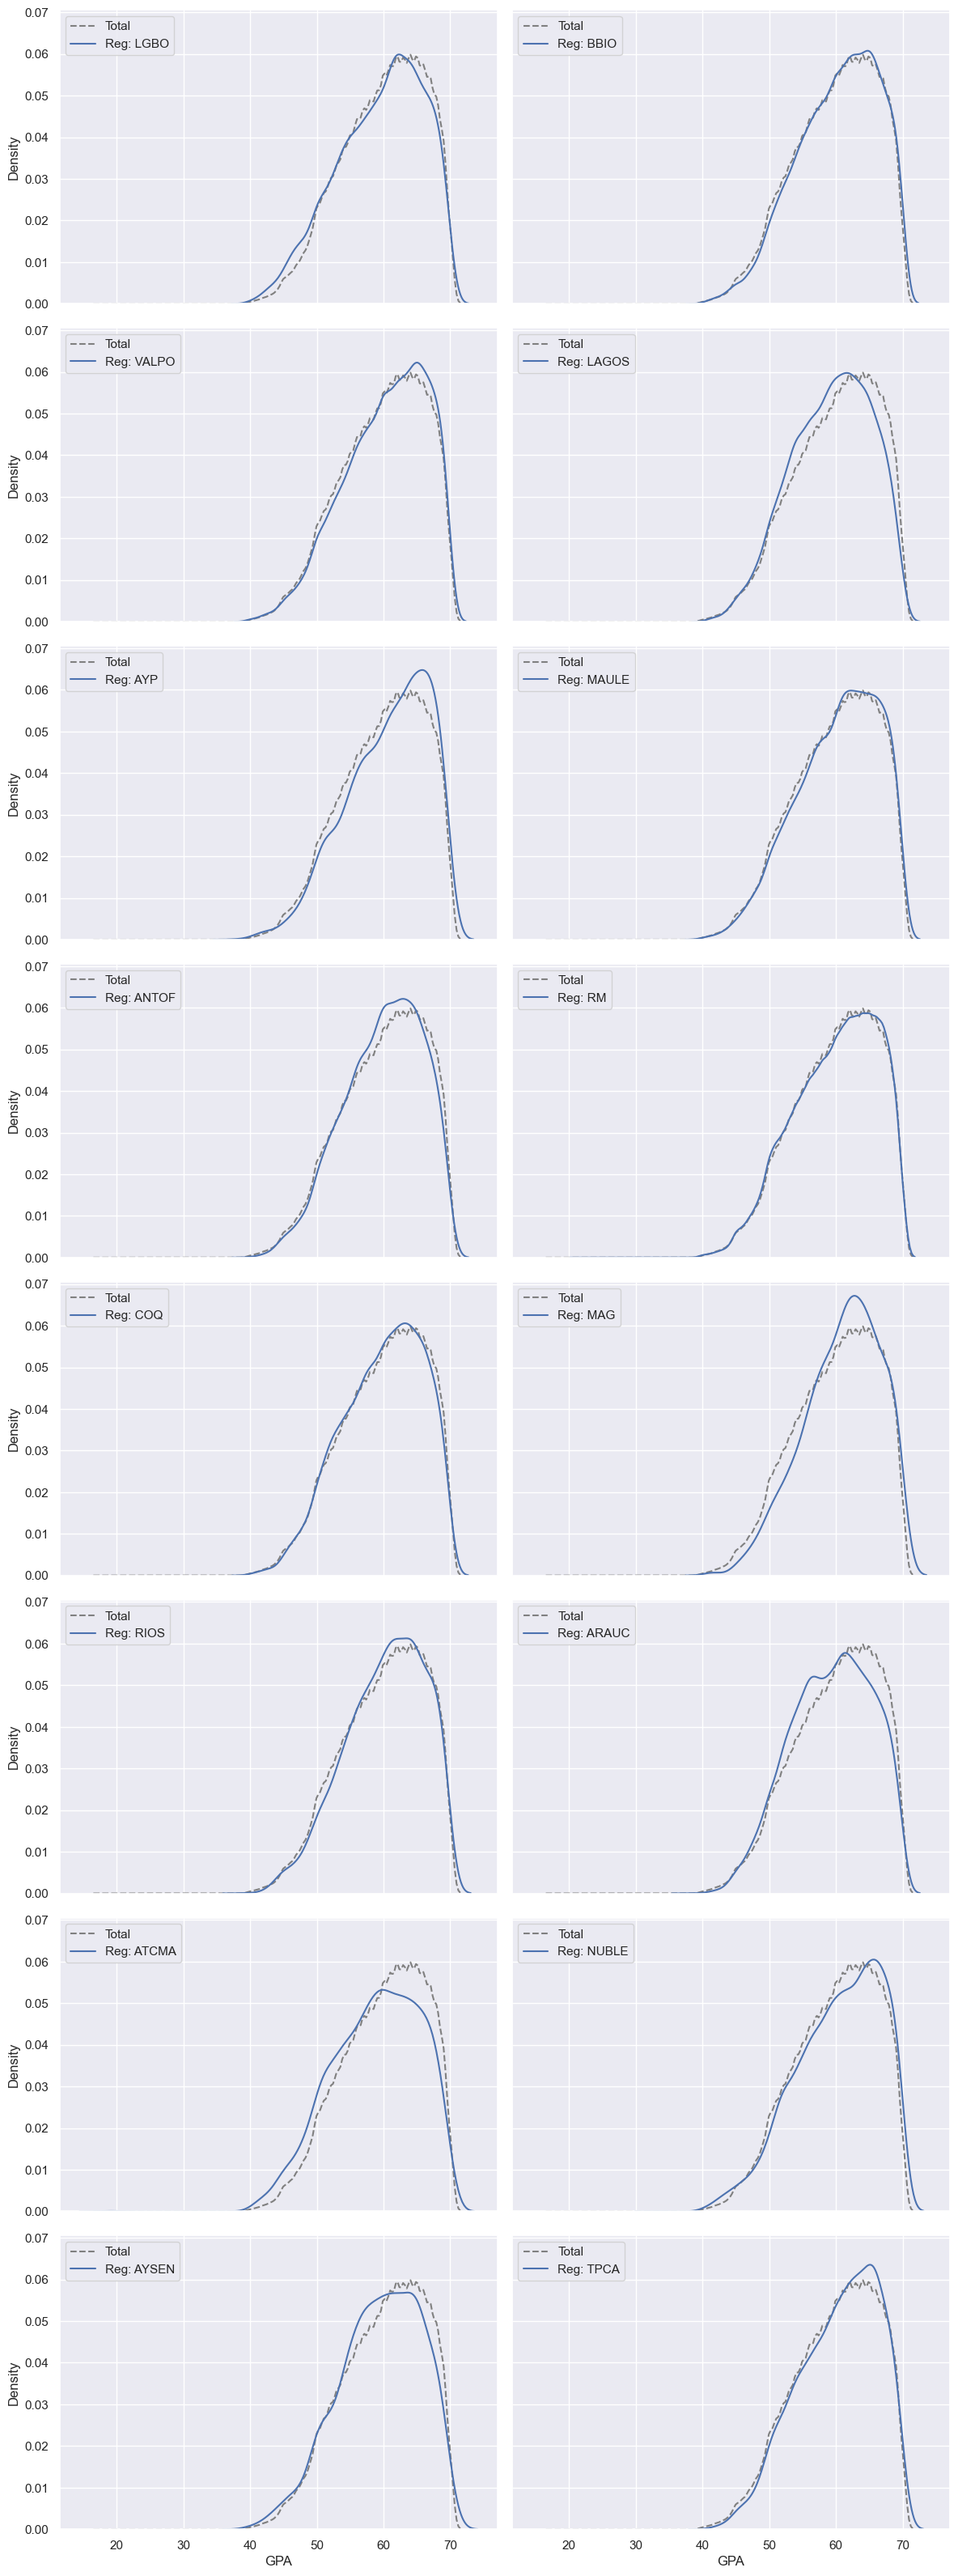

In [120]:
regiones = dfc['Region'].unique()
fig, axes = plt.subplots(
    math.ceil(len(regiones) / 2),
    2,
    figsize=(12, 4 * math.ceil(len(regiones) / 2)),
    sharex=True,
    sharey=True,)

for ax, reg in zip(axes.flatten(), regiones):
    sns.kdeplot(data=dfc, x='GPA', ax=ax, color='gray', ls='--', label='Total')
    sns.kdeplot(data=dfc[dfc['Region'] == reg], x='GPA', ax=ax, label=f'Reg: {reg}')
    ax.legend()

plt.tight_layout()
plt.show()

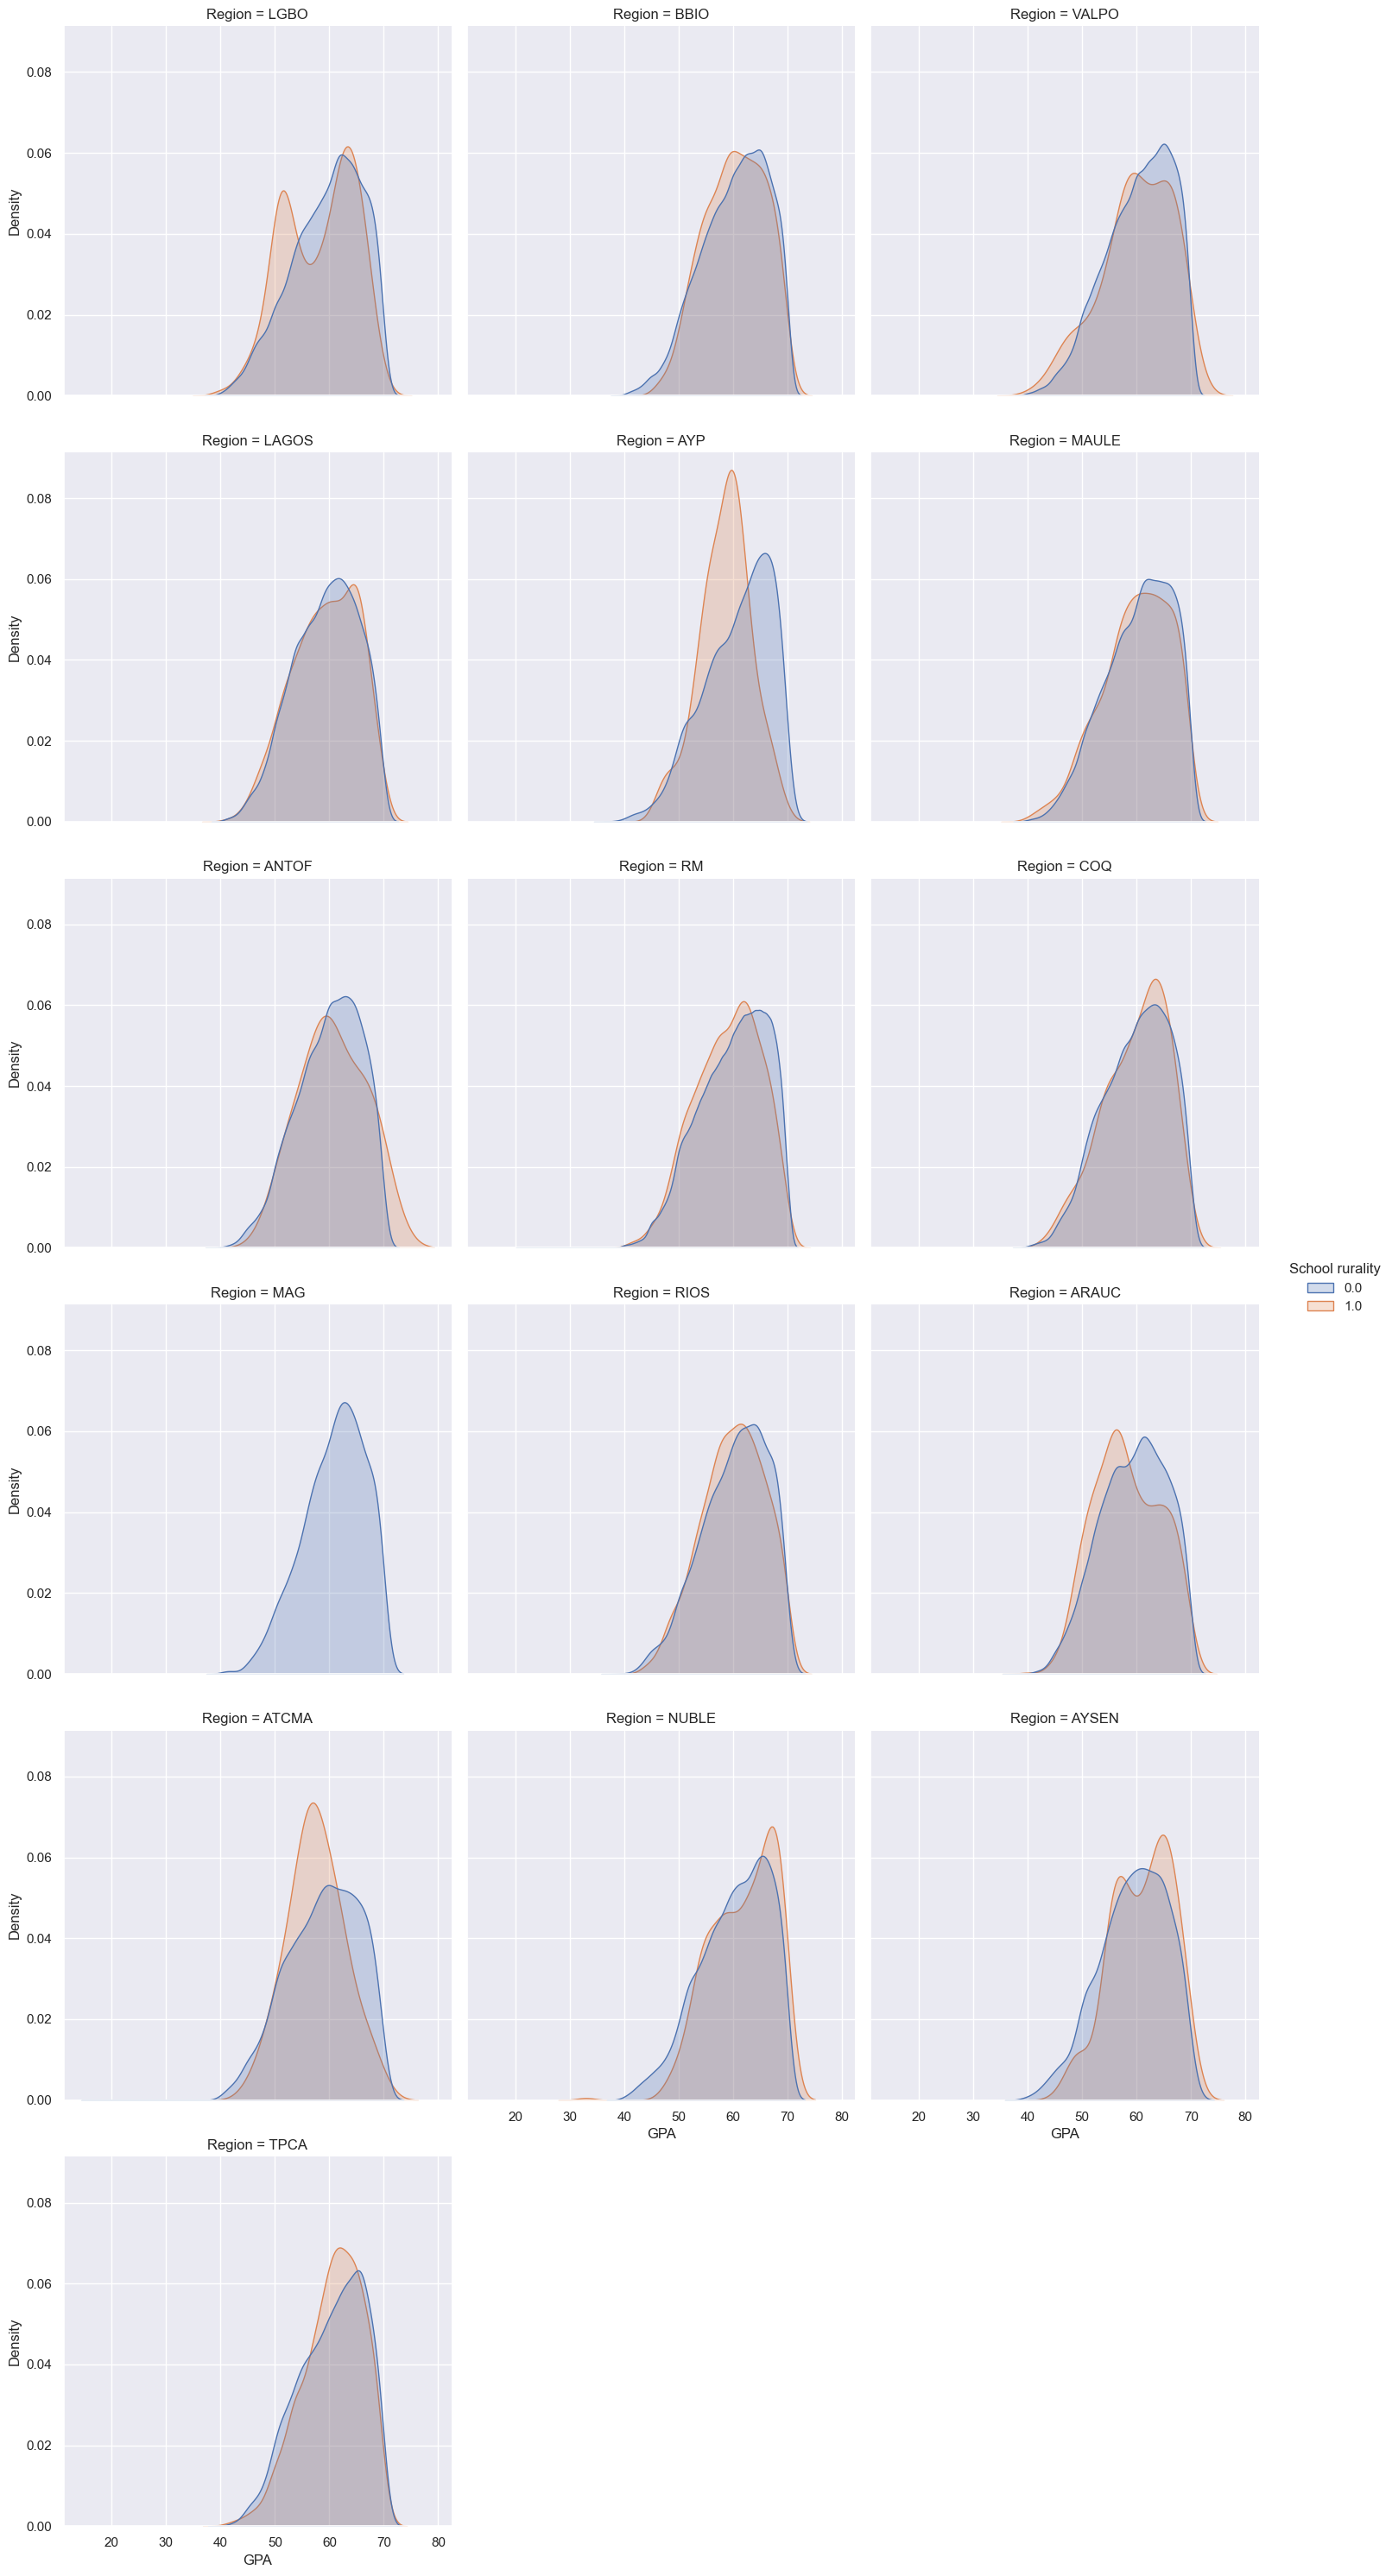

In [119]:
g = sns.displot(
    data=dfc,
    x='GPA',
    hue="School rurality",
    col='Region',          
    col_wrap=3,            
    kind='kde',            
    common_norm=False,
    fill=True)

plt.show()

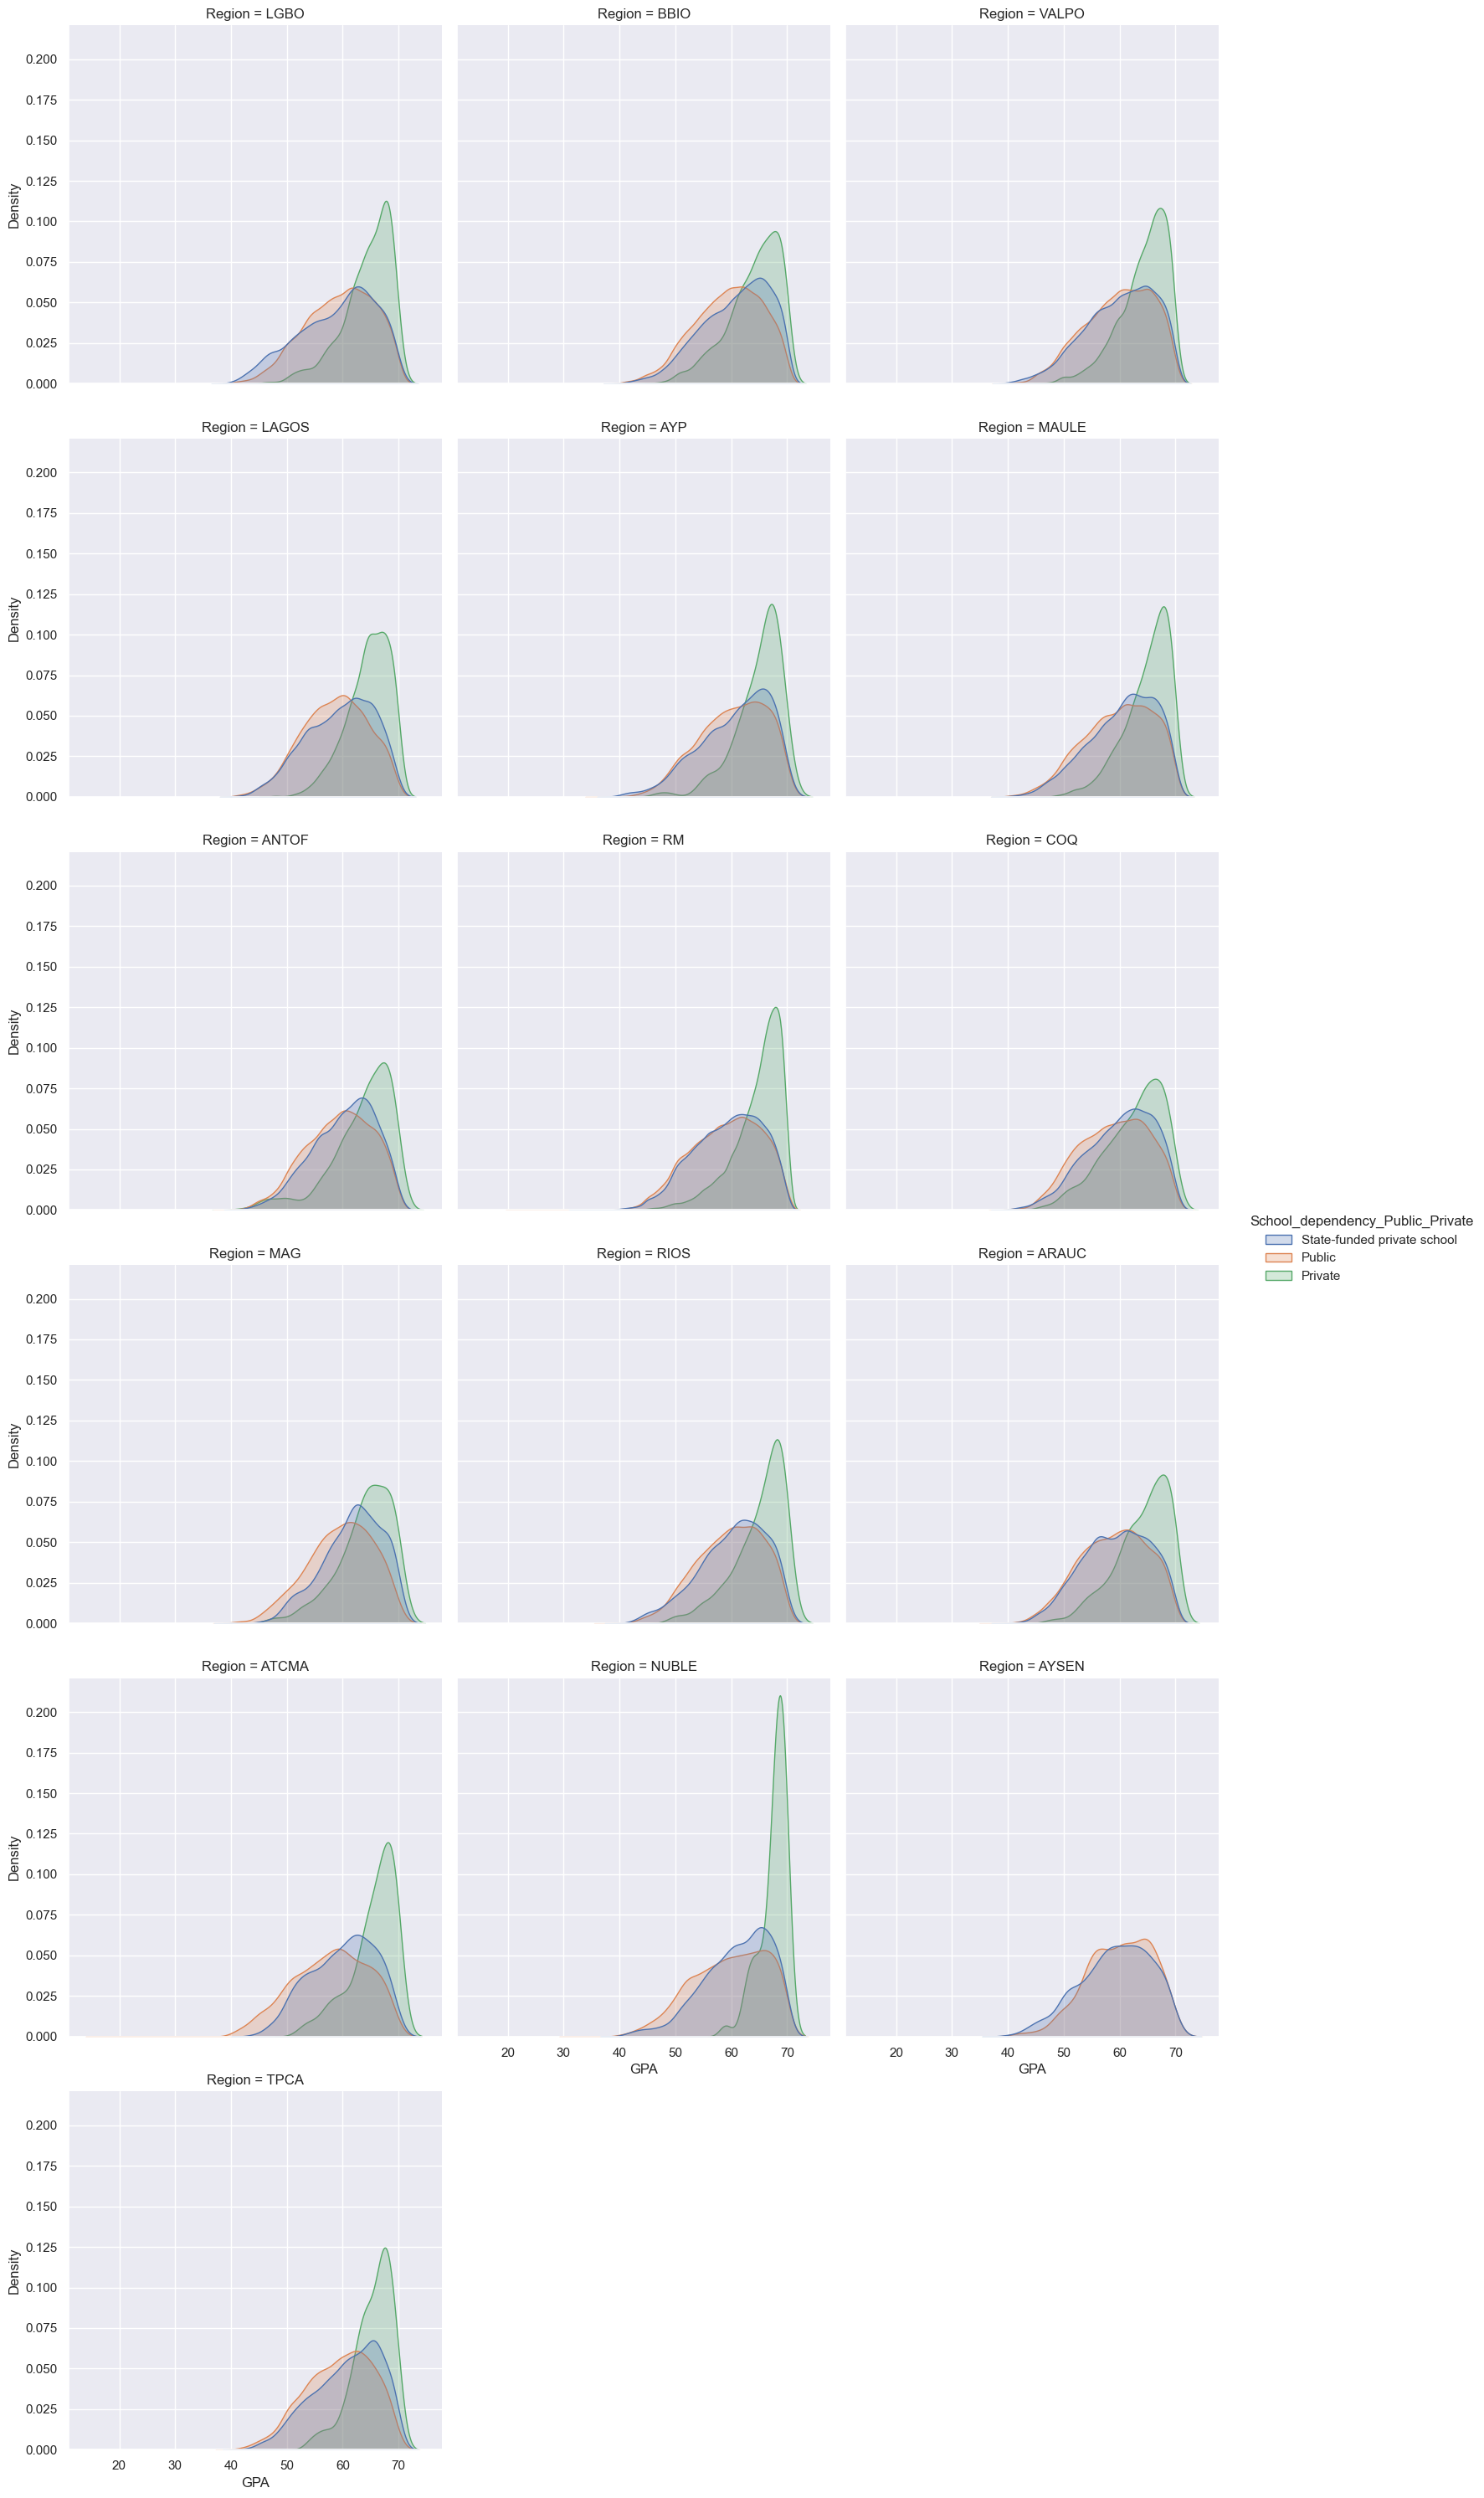

In [34]:
g = sns.displot(
    data=dfc,
    x='GPA',
    hue="School_dependency_Public_Private",
    col='Region',          # Crea una columna por cada valor único de Region
    col_wrap=3,            # Opcional: número máximo de columnas por fila
    kind='kde',            # Especifica que es un gráfico KDE
    common_norm=False,
    fill=True
)

plt.show()

In [128]:
promedios_municipales = ( dfc.groupby('Municipality')['GPA'].mean().reset_index(name='promedio_comunal'))
umbral_top_5 = promedios_municipales['promedio_comunal'].quantile(0.95)
top_5_comunas = promedios_municipales[promedios_municipales['promedio_comunal'] >= umbral_top_5].sort_values(by='promedio_comunal', ascending=False)
print(top_5_comunas.to_string(index=False))

  Municipality  promedio_comunal
      VITACURA         64.970547
  LO BARNECHEA         64.225722
         LOLOL         64.155556
      QUIRIHUE         63.764706
      LA REINA         63.520661
CABO DE HORNOS         63.333333
    LAS CONDES         63.237531
      PAIGUANO         62.939394
      TREHUACO         62.887324
     EMPEDRADO         62.852459
    MEJILLONES         62.824885
   PROVIDENCIA         62.769032
    PORTEZUELO         62.718750
       FLORIDA         62.711268
        CANELA         62.666667
        MALLOA         62.575342
    HUECHURABA         62.527746


In [129]:
umbral_bottom_5 = promedios_municipales['promedio_comunal'].quantile(0.05)
bottom_5_comunas = promedios_municipales[promedios_municipales['promedio_comunal'] <= umbral_bottom_5].sort_values(by='promedio_comunal', ascending=True)
print(bottom_5_comunas.to_string(index=False))

   Municipality  promedio_comunal
       PENCAHUE         52.314286
       COLCHANE         54.750000
        ERCILLA         55.158730
       EL MONTE         55.745161
         NINHUE         55.878173
       CHAÑARAL         55.917391
     CURARREHUE         56.151515
        RENAICO         56.448598
TIERRA AMARILLA         56.600000
       PLACILLA         56.666667
      RINCONADA         56.857143
         CATEMU         56.902174
       PELLUHUE         57.023669
         COLBÚN         57.267857
       COIHUECO         57.343662
      SAN PEDRO         57.386364
PADRE LAS CASAS         57.409426


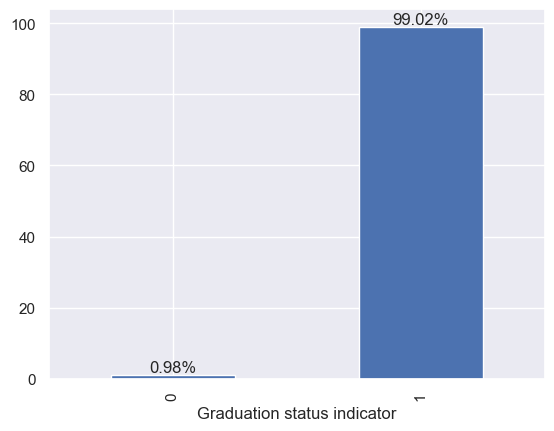

In [134]:
ax = (dfc["Graduation status indicator"].value_counts(normalize=True).sort_index() * 100).plot(kind="bar")
ax.bar_label(ax.containers[0], fmt='%.2f%%')
plt.show()

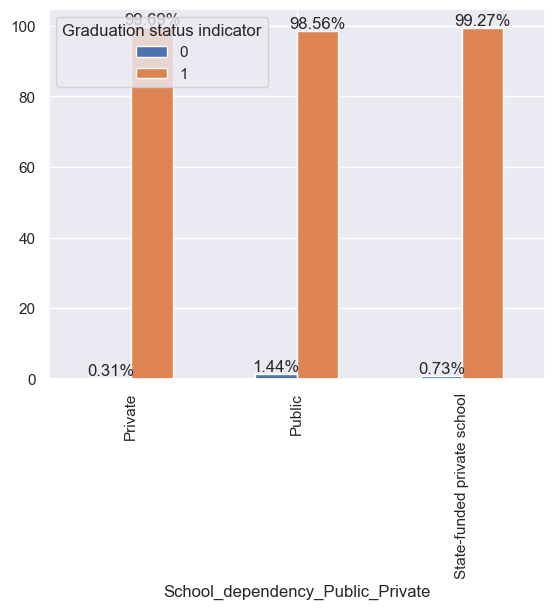

In [135]:
ax = (pd.crosstab(dfc['School_dependency_Public_Private'], dfc['Graduation status indicator'], normalize='index') * 100).plot(kind='bar')
[ax.bar_label(c, fmt='%.2f%%') for c in ax.containers]
plt.show()

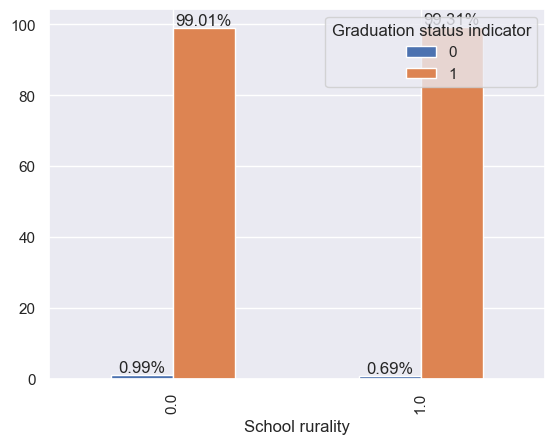

In [136]:
ax = (pd.crosstab(dfc['School rurality'], dfc['Graduation status indicator'], normalize='index') * 100).plot(kind='bar')
[ax.bar_label(c, fmt='%.2f%%') for c in ax.containers]
plt.show()

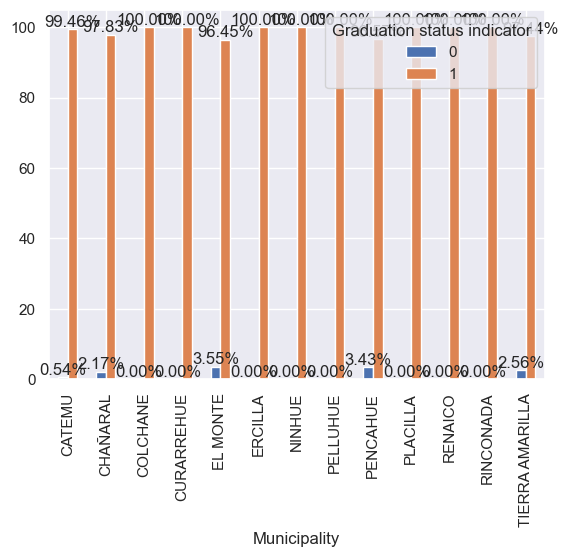

In [138]:
comunas = ["PENCAHUE", "COLCHANE", "ERCILLA", "EL MONTE", "NINHUE", "CHAÑARAL", "CURARREHUE", "RENAICO", "TIERRA AMARILLA", "PLACILLA", "RINCONADA", "CATEMU", "PELLUHUE"]
ax = (pd.crosstab(dfc[dfc["Municipality"].isin(comunas)]["Municipality"], dfc["Graduation status indicator"], normalize="index") * 100).plot(kind="bar")
[ax.bar_label(c, fmt="%.2f%%") for c in ax.containers]
plt.show()

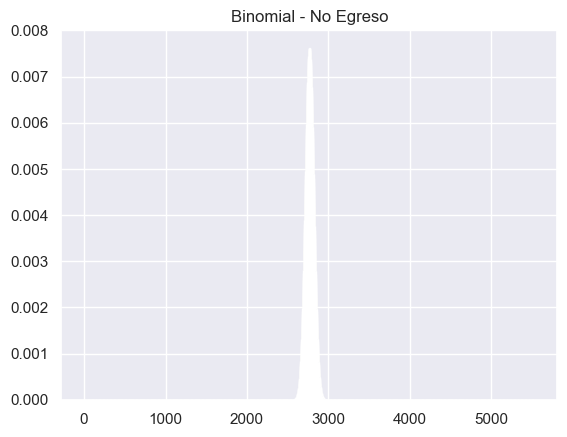

In [139]:
from scipy.stats import binom
n, k = len(dfc), (dfc["Graduation status indicator"] == 0).sum()
p = k / n if n > 0 else 0
plt.bar(range(0, max(10, int(n * p * 2))), binom.pmf(range(0, max(10, int(n * p * 2))), n, p))
plt.title("Binomial - No Egreso")
plt.show()

In [88]:
dfc_rural = dfc[dfc["School rurality"] == 1]
n_rural = len(dfc_rural)
k_no_egresa = (dfc_rural["Graduation status indicator"] == 0).sum()
lambda_no_egreso = n_rural * (k_no_egresa / n_rural) if n_rural > 0 else 0

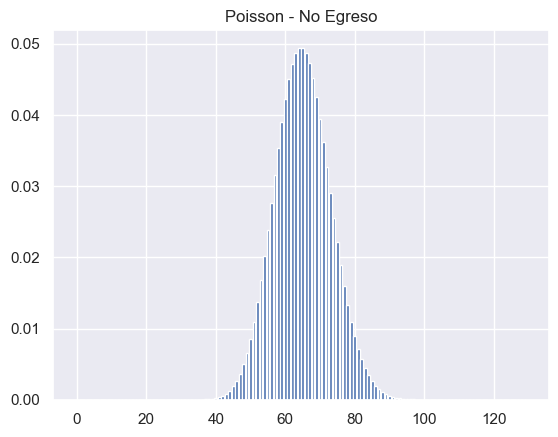

In [89]:
x2 = range(0, max(10, int(lambda_no_egreso * 2)))
plt.bar(x2, poisson.pmf(x2, lambda_no_egreso))
plt.title("Poisson - No Egreso")
plt.show()

In [112]:
sample_sizes = [5, 50, 500,5000,50000]
sample_means = {}

for size in sample_sizes:
    means = [np.mean(np.random.choice(dfc['GPA'], size=size, replace=False)) for _ in range(10000)]
    sample_means[size] = means


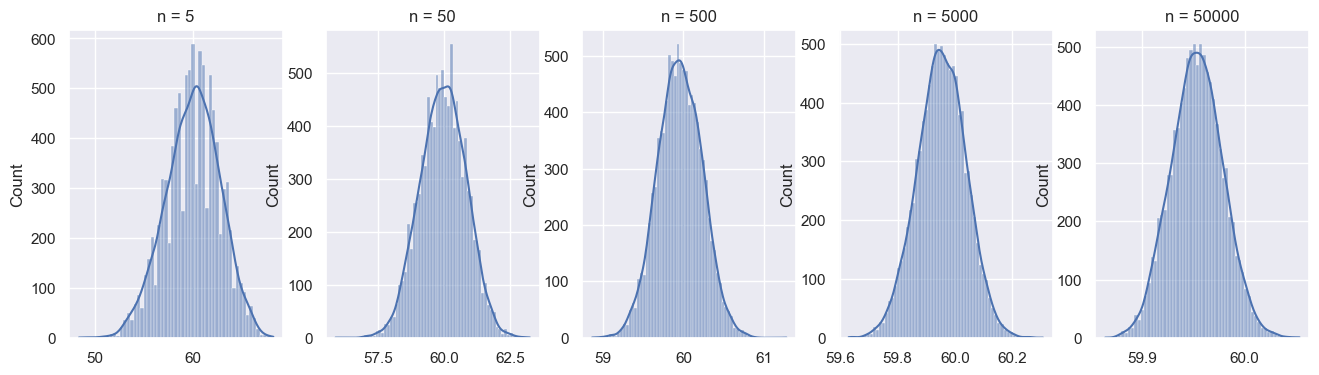

In [114]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for i, size in enumerate(sample_sizes):
    sns.histplot(sample_means[size], kde=True, ax=axes[i])
    axes[i].set_title(f'n = {size}')
plt.show()